In [4]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt
%matplotlib inline

# Define inputs (survey metrics) and output (overall satisfaction)
wait_time = ctrl.Antecedent(np.arange(0, 31, 1), 'wait_time') # 0 to 30 minutes
crowding = ctrl.Antecedent(np.arange(0, 11, 1), 'crowding')   # 0 to 10 scale
satisfaction = ctrl.Consequent(np.arange(0, 101, 1), 'satisfaction') # 0 to 100%

# Automatically populate membership functions (3 categories each)
wait_time.automf(3, names=['short', 'medium', 'long'])
crowding.automf(3, names=['low', 'moderate', 'high'])
satisfaction.automf(3, names=['low', 'medium', 'high'])

Establish Rules and the Control System

In [5]:
# Map the fuzzy survey inputs to the fuzzy satisfaction output
rule1 = ctrl.Rule(wait_time['long'] | crowding['high'], satisfaction['low'])
rule2 = ctrl.Rule(wait_time['medium'] & crowding['moderate'], satisfaction['medium'])
rule3 = ctrl.Rule(wait_time['short'] & crowding['low'], satisfaction['high'])

# Build the simulation system
survey_ctrl = ctrl.ControlSystem([rule1, rule2, rule3])
survey_sim = ctrl.ControlSystemSimulation(survey_ctrl)

Defuzzified Satisfaction Score: 41.2/100

--- Natural Language Summary ---
Passenger sentiment is neutral; transit service levels are acceptable but show room for operational improvement.


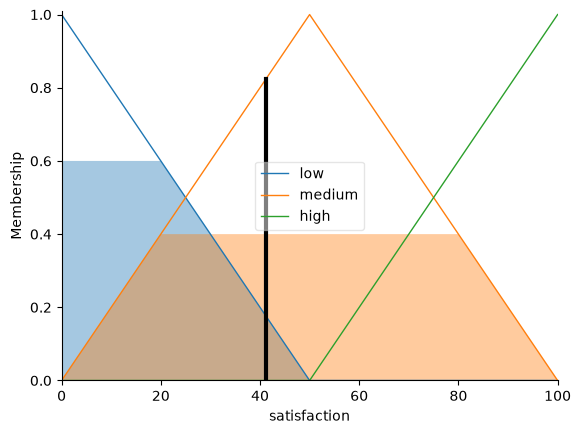

In [6]:
# Input mock passenger survey data
survey_sim.input['wait_time'] = 22  # Waited 22 minutes
survey_sim.input['crowding'] = 8    # Crowding rated 8 out of 10

# Compute the fuzzy logic
survey_sim.compute()
score = survey_sim.output['satisfaction']

print(f"Defuzzified Satisfaction Score: {score:.1f}/100")
satisfaction.view(sim=survey_sim)

# Translate the numerical output into a text summary
print("\n--- Natural Language Summary ---")
if score < 33.3:
    print("Passengers report severe dissatisfaction, primarily driven by excessive wait times and overcrowded conditions.")
elif score < 66.6:
    print("Passenger sentiment is neutral; transit service levels are acceptable but show room for operational improvement.")
else:
    print("Passengers are highly satisfied, experiencing efficient boarding and comfortable transit conditions.")